In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/train.csv')

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
# Generate statistical summary
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
# Statistical summary of categorical columns
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [5]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate percentage of missing values
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Value Percentage:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [6]:
# Count survived and non-survived passengers
print(df['Survived'].value_counts())

# Display survival percentages
print("\nSurvival Percentage:")
print(df['Survived'].value_counts(normalize=True) * 100)

Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


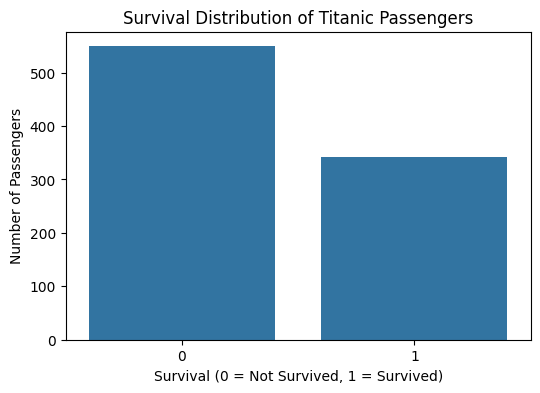

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Survived')

plt.title('Survival Distribution of Titanic Passengers')
plt.xlabel('Survival (0 = Not Survived, 1 = Survived)')
plt.ylabel('Number of Passengers')

plt.show()

In [8]:
# Count survival based on gender
print(df.groupby('Sex')['Survived'].value_counts())

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64


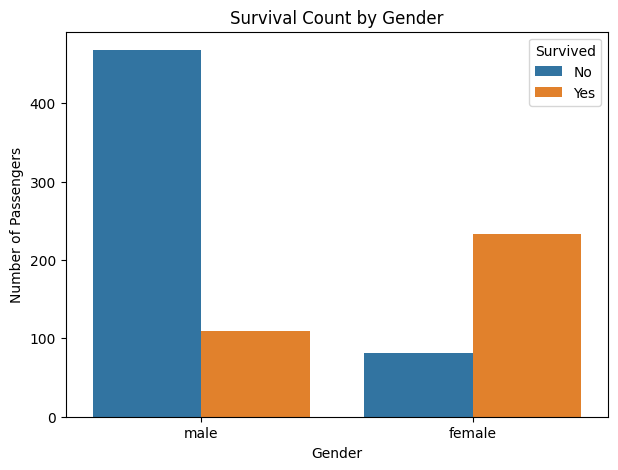

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.legend(title='Survived', labels=['No', 'Yes'])

plt.show()

In [10]:
# Analyze survival based on passenger class
print(df.groupby('Pclass')['Survived'].value_counts())

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64


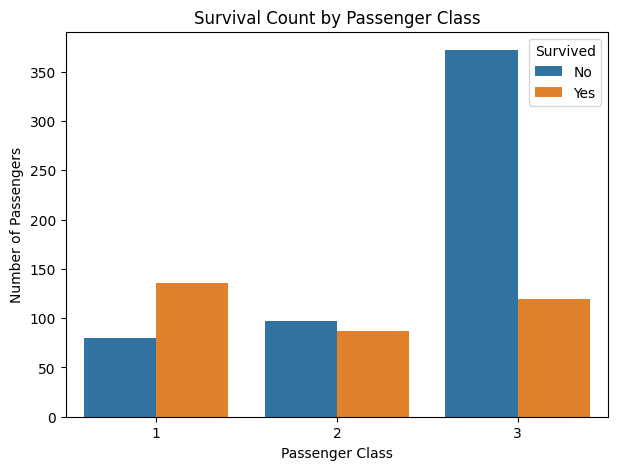

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.legend(title='Survived', labels=['No', 'Yes'])

plt.show()

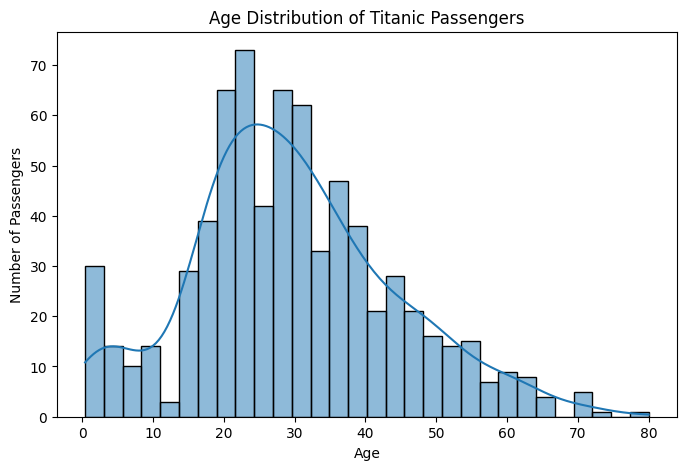

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

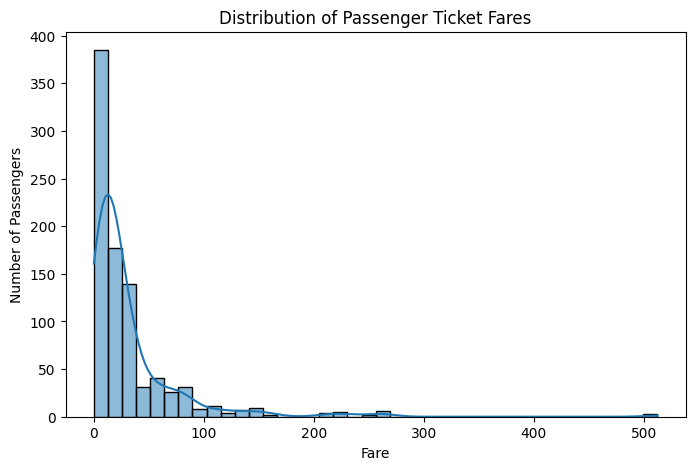

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Fare', bins=40, kde=True)

plt.title('Distribution of Passenger Ticket Fares')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')

plt.show()

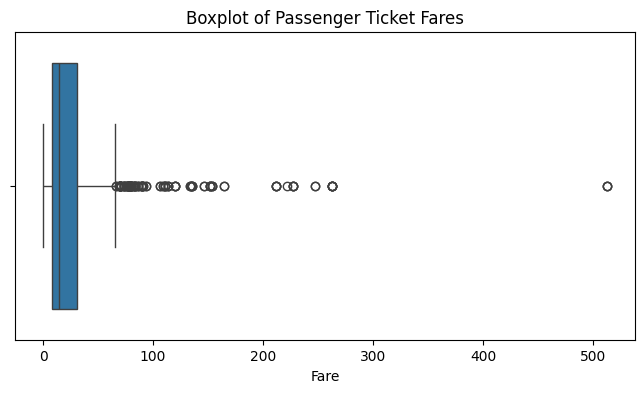

In [14]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='Fare')

plt.title('Boxplot of Passenger Ticket Fares')
plt.xlabel('Fare')

plt.show()

In [15]:
# Calculate correlation between numerical columns
correlation = df.corr(numeric_only=True)

print(correlation)

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005007 -0.035144  0.036847 -0.057527 -0.001652   
Survived       -0.005007  1.000000 -0.338481 -0.077221 -0.035322  0.081629   
Pclass         -0.035144 -0.338481  1.000000 -0.369226  0.083081  0.018443   
Age             0.036847 -0.077221 -0.369226  1.000000 -0.308247 -0.189119   
SibSp          -0.057527 -0.035322  0.083081 -0.308247  1.000000  0.414838   
Parch          -0.001652  0.081629  0.018443 -0.189119  0.414838  1.000000   
Fare            0.012658  0.257307 -0.549500  0.096067  0.159651  0.216225   

                 Fare  
PassengerId  0.012658  
Survived     0.257307  
Pclass      -0.549500  
Age          0.096067  
SibSp        0.159651  
Parch        0.216225  
Fare         1.000000  


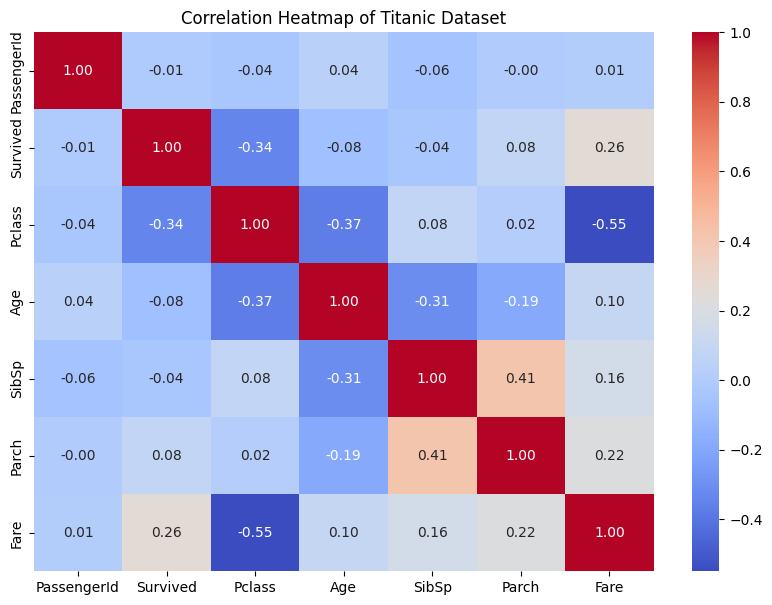

In [16]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Titanic Dataset')

plt.show()

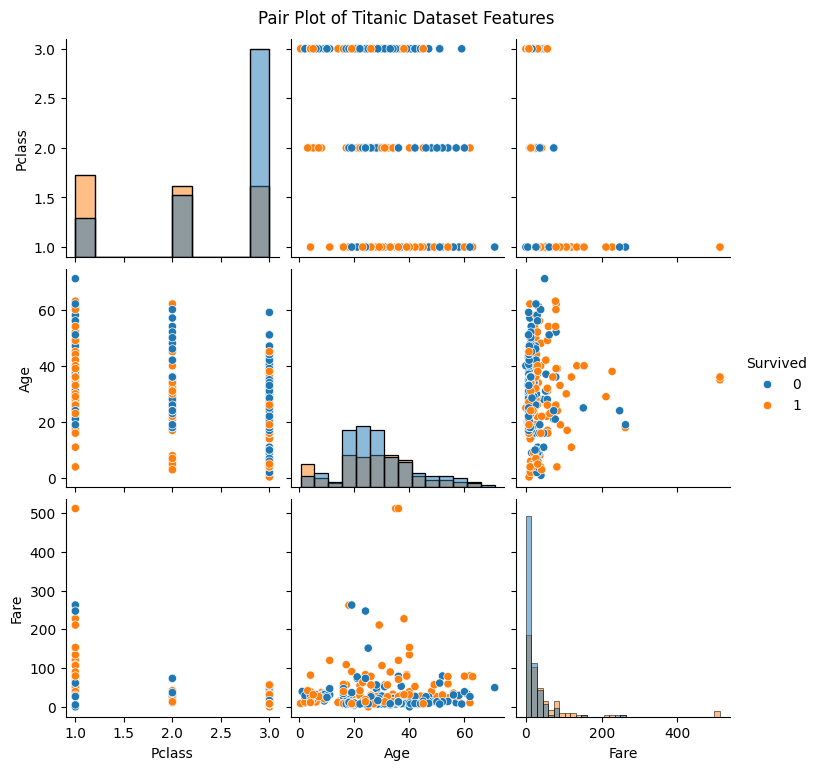

In [17]:
# Select important numerical columns
pair_data = df[['Survived', 'Pclass', 'Age', 'Fare']].dropna()

# Create pair plot
sns.pairplot(pair_data.sample(300, random_state=42),
             hue='Survived',
             diag_kind='hist')

plt.suptitle('Pair Plot of Titanic Dataset Features', y=1.02)

plt.show()

In [18]:
# Calculate survival rate by gender
gender_survival = df.groupby('Sex')['Survived'].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival)

# Calculate survival rate by passenger class
class_survival = df.groupby('Pclass')['Survived'].mean() * 100

print("\nSurvival Rate by Passenger Class:")
print(class_survival)

Survival Rate by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [19]:
# Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Children', 'Teenagers', 'Young Adults', 'Adults', 'Senior Citizens']
)

# Calculate survival rate by age group
age_survival = df.groupby('AgeGroup', observed=False)['Survived'].mean() * 100

print("Survival Rate by Age Group:")
print(age_survival)

Survival Rate by Age Group:
AgeGroup
Children           57.971014
Teenagers          42.857143
Young Adults       38.268156
Adults             40.000000
Senior Citizens    22.727273
Name: Survived, dtype: float64


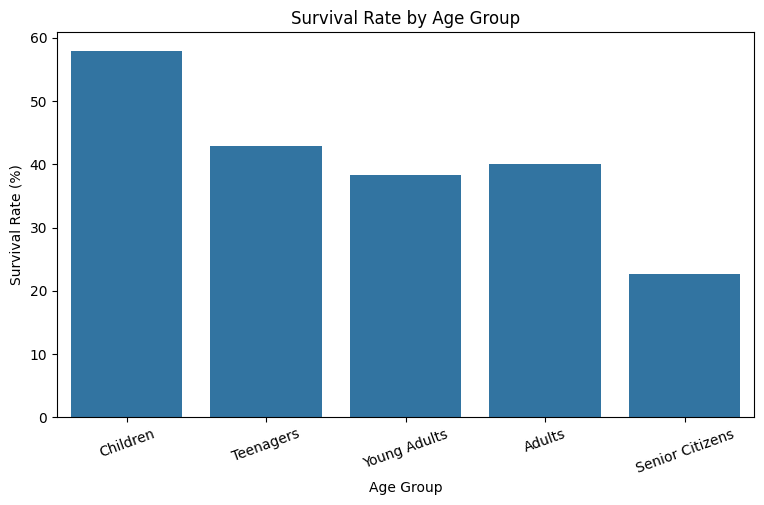

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(x=age_survival.index, y=age_survival.values)

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=20)

plt.show()

In [21]:
# Calculate survival rate by embarkation port
embarked_survival = df.groupby('Embarked')['Survived'].mean() * 100

print("Survival Rate by Embarkation Port:")
print(embarked_survival)

Survival Rate by Embarkation Port:
Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64


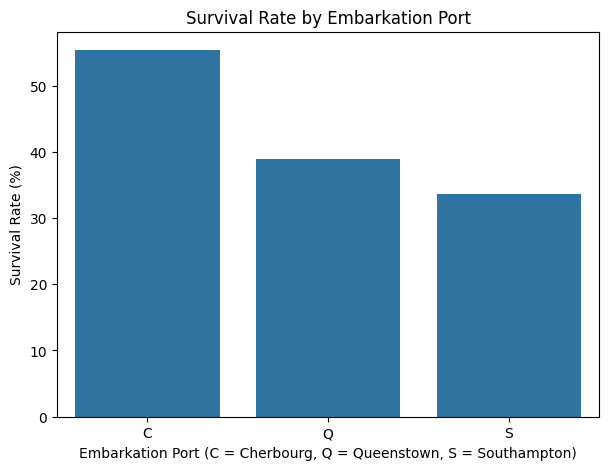

In [22]:
plt.figure(figsize=(7, 5))

sns.barplot(x=embarked_survival.index, y=embarked_survival.values)

plt.title('Survival Rate by Embarkation Port')
plt.xlabel('Embarkation Port (C = Cherbourg, Q = Queenstown, S = Southampton)')
plt.ylabel('Survival Rate (%)')

plt.show()

In [23]:
print("TITANIC DATASET - EDA SUMMARY")
print("--------------------------------")

print("Total Passengers:", len(df))

print("\nSurvival Count:")
print(df['Survived'].value_counts())

print("\nSurvival Rate by Gender:")
print((df.groupby('Sex')['Survived'].mean() * 100).round(2))

print("\nSurvival Rate by Passenger Class:")
print((df.groupby('Pclass')['Survived'].mean() * 100).round(2))

print("\nAverage Passenger Age:", round(df['Age'].mean(), 2))

print("Average Ticket Fare:", round(df['Fare'].mean(), 2))

TITANIC DATASET - EDA SUMMARY
--------------------------------
Total Passengers: 891

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Average Passenger Age: 29.7
Average Ticket Fare: 32.2
